In [4]:
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [5]:
data = pd.read_csv('/kaggle/input/veremi-extension-mendelydata/Vermi.csv')

In [6]:
data.columns

Index(['type', 'sendTime', 'sender', 'senderPseudo', 'messageID', 'class',
       'posx', 'posy', 'posz', 'posx_n', 'posy_n', 'posz_n', 'spdx', 'spdy',
       'spdz', 'spdx_n', 'spdy_n', 'spdz_n', 'aclx', 'acly', 'aclz', 'aclx_n',
       'acly_n', 'aclz_n', 'hedx', 'hedy', 'hedz', 'hedx_n', 'hedy_n',
       'hedz_n'],
      dtype='object')

In [7]:
'''from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_regression

X = data.drop(columns=['class'])  # Features
y = data['class']  # Target variable

# Perform correlation-based feature selection using SelectKBest with f_regression
selector = SelectKBest(score_func=f_regression, k=12)  # Select top 2 features
X_selected = selector.fit_transform(X, y)

# Get the selected feature names
selected_feature_names = X.columns[selector.get_support()]

print("Selected features:", selected_feature_names)'''


'from sklearn.feature_selection import SelectKBest\nfrom sklearn.feature_selection import f_regression\n\nX = data.drop(columns=[\'class\'])  # Features\ny = data[\'class\']  # Target variable\n\n# Perform correlation-based feature selection using SelectKBest with f_regression\nselector = SelectKBest(score_func=f_regression, k=12)  # Select top 2 features\nX_selected = selector.fit_transform(X, y)\n\n# Get the selected feature names\nselected_feature_names = X.columns[selector.get_support()]\n\nprint("Selected features:", selected_feature_names)'

In [8]:
"""import pandas as pd
from sklearn.feature_selection import RFE
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Assuming 'data' is your existing DataFrame with features and target variable
X = data.drop(columns=['class'])  # Features
y = data['class']  # Target variable

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize the model (estimator)
estimator = LinearRegression()  # Number of features to select
rfe = RFE(estimator, n_features_to_select=12)

# Fit RFE
rfe.fit(X_train, y_train)

# Get selected features
selected_features = X.columns[rfe.support_]

print("Selected features:", selected_features)"""


'import pandas as pd\nfrom sklearn.feature_selection import RFE\nfrom sklearn.model_selection import train_test_split\nfrom sklearn.linear_model import LinearRegression\n\n# Assuming \'data\' is your existing DataFrame with features and target variable\nX = data.drop(columns=[\'class\'])  # Features\ny = data[\'class\']  # Target variable\n\n# Split data into training and testing sets\nX_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)\n\n# Initialize the model (estimator)\nestimator = LinearRegression()  # Number of features to select\nrfe = RFE(estimator, n_features_to_select=12)\n\n# Fit RFE\nrfe.fit(X_train, y_train)\n\n# Get selected features\nselected_features = X.columns[rfe.support_]\n\nprint("Selected features:", selected_features)'

In [9]:
"""from sklearn.linear_model import Lasso
from sklearn.model_selection import train_test_split

# Assuming 'data' is your existing DataFrame with features and target variable
X = data.drop(columns=['class'])  # Features
y = data['class']  # Target variable

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize and fit Lasso regression model
lasso = Lasso(alpha=0.1)  # You can adjust alpha (regularization strength) as needed
lasso.fit(X_train, y_train)

# Get selected features
selected_features = X.columns[lasso.coef_ != 0]

print("Selected features:", selected_features)
"""

'from sklearn.linear_model import Lasso\nfrom sklearn.model_selection import train_test_split\n\n# Assuming \'data\' is your existing DataFrame with features and target variable\nX = data.drop(columns=[\'class\'])  # Features\ny = data[\'class\']  # Target variable\n\n# Split data into training and testing sets\nX_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)\n\n# Initialize and fit Lasso regression model\nlasso = Lasso(alpha=0.1)  # You can adjust alpha (regularization strength) as needed\nlasso.fit(X_train, y_train)\n\n# Get selected features\nselected_features = X.columns[lasso.coef_ != 0]\n\nprint("Selected features:", selected_features)\n'

In [10]:
data.columns

Index(['type', 'sendTime', 'sender', 'senderPseudo', 'messageID', 'class',
       'posx', 'posy', 'posz', 'posx_n', 'posy_n', 'posz_n', 'spdx', 'spdy',
       'spdz', 'spdx_n', 'spdy_n', 'spdz_n', 'aclx', 'acly', 'aclz', 'aclx_n',
       'acly_n', 'aclz_n', 'hedx', 'hedy', 'hedz', 'hedx_n', 'hedy_n',
       'hedz_n'],
      dtype='object')

In [11]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3194808 entries, 0 to 3194807
Data columns (total 30 columns):
 #   Column        Dtype  
---  ------        -----  
 0   type          int64  
 1   sendTime      float64
 2   sender        int64  
 3   senderPseudo  int64  
 4   messageID     int64  
 5   class         int64  
 6   posx          float64
 7   posy          float64
 8   posz          float64
 9   posx_n        float64
 10  posy_n        float64
 11  posz_n        float64
 12  spdx          float64
 13  spdy          float64
 14  spdz          float64
 15  spdx_n        float64
 16  spdy_n        float64
 17  spdz_n        float64
 18  aclx          float64
 19  acly          float64
 20  aclz          float64
 21  aclx_n        float64
 22  acly_n        float64
 23  aclz_n        float64
 24  hedx          float64
 25  hedy          float64
 26  hedz          float64
 27  hedx_n        float64
 28  hedy_n        float64
 29  hedz_n        float64
dtypes: float64(25), in

In [12]:
data['class'].value_counts()

class
0     1900539
16     175391
13     131305
15     129270
14     126724
18      86883
19      82100
6       44359
11      44337
17      44310
3       43857
1       43653
2       43567
10      43264
12      43118
9       42790
8       42583
4       42575
7       42258
5       41925
Name: count, dtype: int64

In [13]:
def binarize_values(val):
    return 0 if val == 0 else 1

data['binaryClass'] = data['class'].apply(binarize_values)

In [14]:
data['binaryClass'].value_counts()

binaryClass
0    1900539
1    1294269
Name: count, dtype: int64

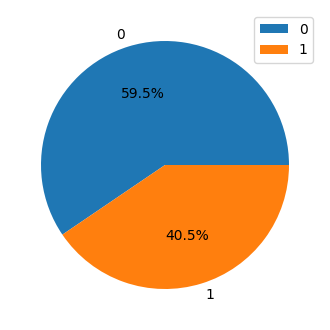

In [15]:
class_counts = data['binaryClass'].value_counts()
plt.figure(figsize=(4, 6))
plt.pie(class_counts, labels=class_counts.index, autopct='%1.1f%%', startangle=0)
hfont = {'fontname':'serif', 'weight': 'bold'}
plt.legend()

plt.show()

In [16]:
data.head(5)

,type,sendTime,sender,senderPseudo,messageID,class,posx,posy,posz,posx_n,...,aclx_n,acly_n,aclz_n,hedx,hedy,hedz,hedx_n,hedy_n,hedz_n,binaryClass
0,4,72002.302942,130137,101301377,422013806,0,266.982401,32.336955,0.0,3.480882,...,0.000862,0.000862,0.0,-0.102790,0.994703,0.0,20.038218,17.541001,0.0,0
1,4,72003.302942,130137,101301377,422023410,0,266.827208,34.624145,0.0,3.546261,...,0.000107,0.001040,0.0,-0.099856,0.995002,0.0,20.441139,14.467283,0.0,0
2,4,72004.302942,130137,101301377,422032081,0,266.420297,38.836461,0.0,3.544045,...,0.000172,0.001661,0.0,-0.099856,0.995002,0.0,20.850473,11.941528,0.0,0
3,4,72005.302942,130137,101301377,422040712,0,268.912026,45.414229,0.0,3.340080,...,0.000171,0.001654,0.0,-0.100172,0.994970,0.0,21.323229,9.633965,0.0,0
4,4,72006.302942,130137,101301377,422052949,0,268.242276,53.729986,0.0,3.328872,...,0.000193,0.001852,0.0,-0.097105,0.995274,0.0,21.788034,7.824555,0.0,0


In [17]:
data['type'].unique()

array([4])

In [18]:
to_drop = ['type','senderPseudo','messageID','posz','spdz','aclz','hedz','posz_n','spdz_n','aclz_n','hedz_n']
data.drop(to_drop, axis=1, inplace=True)
data.head(3)

,sendTime,sender,class,posx,posy,posx_n,posy_n,spdx,spdy,spdx_n,spdy_n,aclx,acly,aclx_n,acly_n,hedx,hedy,hedx_n,hedy_n,binaryClass
0,72002.302942,130137,0,266.982401,32.336955,3.480882,3.473184,-0.124661,1.206343,-0.000000,-0.000000,-0.219100,2.120328,0.000862,0.000862,-0.102790,0.994703,20.038218,17.541001,0
1,72003.302942,130137,0,266.827208,34.624145,3.546261,3.570524,-0.323739,3.132858,0.000107,-0.001040,-0.216966,2.099684,0.000107,0.001040,-0.099856,0.995002,20.441139,14.467283,0
2,72004.302942,130137,0,266.420297,38.836461,3.544045,3.432068,-0.522008,5.051538,0.000279,-0.002701,-0.184437,1.784944,0.000172,0.001661,-0.099856,0.995002,20.850473,11.941528,0


In [19]:
data.sort_values(by=['sender','sendTime'], inplace=True)
data.head(5)

,sendTime,sender,class,posx,posy,posx_n,posy_n,spdx,spdy,spdx_n,spdy_n,aclx,acly,aclx_n,acly_n,hedx,hedy,hedx_n,hedy_n,binaryClass
2365422,240.602763,9,0,265.105411,50.751262,4.714697,4.591569,-0.106863,1.034114,-0.000000,-0.000000,-0.252108,2.440102,0.000534,0.000534,-0.093026,0.995664,6.791931,6.059563,0
2365423,241.602763,9,0,264.959604,53.058156,4.826480,4.516395,-0.335474,3.246444,0.000057,-0.000552,-0.173838,1.682665,0.000057,0.000552,-0.093026,0.995664,6.948994,4.856923,0
2365424,242.602763,9,0,264.331427,57.302385,5.004188,4.535059,-0.604297,5.324067,0.000179,-0.001734,-0.301984,2.660974,0.000122,0.001181,-0.098425,0.995144,7.138329,3.945763,0
2365425,243.602763,9,0,263.610633,63.710039,4.890198,4.370803,-0.999298,7.184181,0.000323,-0.002843,-0.196967,1.416335,0.000144,0.001109,-0.122430,0.992477,7.425940,3.276027,0
2365426,244.602763,9,0,262.621917,71.941010,4.968665,4.350376,-1.409192,9.105838,0.000534,-0.003836,-0.291180,1.881746,0.000211,0.000993,-0.137632,0.990483,7.736676,2.703289,0


In [20]:
data['shifted_posx'] = data.groupby('sender')['posx'].shift(1)
data['shifted_posy'] = data.groupby('sender')['posy'].shift(1)


In [21]:
data.head(5)

,sendTime,sender,class,posx,posy,posx_n,posy_n,spdx,spdy,spdx_n,...,acly,aclx_n,acly_n,hedx,hedy,hedx_n,hedy_n,binaryClass,shifted_posx,shifted_posy
2365422,240.602763,9,0,265.105411,50.751262,4.714697,4.591569,-0.106863,1.034114,-0.000000,...,2.440102,0.000534,0.000534,-0.093026,0.995664,6.791931,6.059563,0,NaN,NaN
2365423,241.602763,9,0,264.959604,53.058156,4.826480,4.516395,-0.335474,3.246444,0.000057,...,1.682665,0.000057,0.000552,-0.093026,0.995664,6.948994,4.856923,0,265.105411,50.751262
2365424,242.602763,9,0,264.331427,57.302385,5.004188,4.535059,-0.604297,5.324067,0.000179,...,2.660974,0.000122,0.001181,-0.098425,0.995144,7.138329,3.945763,0,264.959604,53.058156
2365425,243.602763,9,0,263.610633,63.710039,4.890198,4.370803,-0.999298,7.184181,0.000323,...,1.416335,0.000144,0.001109,-0.122430,0.992477,7.425940,3.276027,0,264.331427,57.302385
2365426,244.602763,9,0,262.621917,71.941010,4.968665,4.350376,-1.409192,9.105838,0.000534,...,1.881746,0.000211,0.000993,-0.137632,0.990483,7.736676,2.703289,0,263.610633,63.710039


In [22]:
def calculate_distance(row):
    if row.name == 0:
        return 0
    prev_pos = (row.shifted_posx, row.shifted_posy)
    curr_pos = (row.posx, row.posy)
    return np.sqrt((curr_pos[0] - prev_pos[0])**2 + (curr_pos[1] - prev_pos[1])**2)


In [23]:
data['distance'] = data.apply(calculate_distance, axis=1)

In [24]:
data['timedif'] = data.groupby('sender')['sendTime'].diff().fillna(0).astype(float)
data.head(5)

,sendTime,sender,class,posx,posy,posx_n,posy_n,spdx,spdy,spdx_n,...,acly_n,hedx,hedy,hedx_n,hedy_n,binaryClass,shifted_posx,shifted_posy,distance,timedif
2365422,240.602763,9,0,265.105411,50.751262,4.714697,4.591569,-0.106863,1.034114,-0.000000,...,0.000534,-0.093026,0.995664,6.791931,6.059563,0,NaN,NaN,NaN,0.0
2365423,241.602763,9,0,264.959604,53.058156,4.826480,4.516395,-0.335474,3.246444,0.000057,...,0.000552,-0.093026,0.995664,6.948994,4.856923,0,265.105411,50.751262,2.311497,1.0
2365424,242.602763,9,0,264.331427,57.302385,5.004188,4.535059,-0.604297,5.324067,0.000179,...,0.001181,-0.098425,0.995144,7.138329,3.945763,0,264.959604,53.058156,4.290464,1.0
2365425,243.602763,9,0,263.610633,63.710039,4.890198,4.370803,-0.999298,7.184181,0.000323,...,0.001109,-0.122430,0.992477,7.425940,3.276027,0,264.331427,57.302385,6.448068,1.0
2365426,244.602763,9,0,262.621917,71.941010,4.968665,4.350376,-1.409192,9.105838,0.000534,...,0.000993,-0.137632,0.990483,7.736676,2.703289,0,263.610633,63.710039,8.290142,1.0


In [25]:
data.fillna(0, inplace=True)

In [26]:
def calculate_speed_magnitude(row):
    spdx = row.spdx
    spdy = row.spdy
    speed_magnitude = math.sqrt(spdx**2 + spdy**2)
    return speed_magnitude

In [27]:
data['speed'] = data.apply(calculate_speed_magnitude, axis=1)

In [28]:
data.drop(['shifted_posx','shifted_posy'],axis=1,inplace=True)

In [51]:

train_drop =['sendTime', 'sender', 'class','posx_n','posy_n', 'spdx_n','spdy_n','hedx_n','hedy_n', 'aclx', 'acly', 'aclx_n',
       'acly_n','binaryClass','triClass']


X=data.drop(train_drop,axis=1)
y=data['binaryClass']

In [52]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

In [53]:
DT = DecisionTreeClassifier()
DT.fit(X_train, y_train)

DecisionTreeClassifier()

In [54]:
DT_pred = DT.predict(X_test)
print(classification_report(y_test,DT_pred))

              precision    recall  f1-score   support

           0       0.97      0.97      0.97    570474
           1       0.95      0.95      0.95    387969

    accuracy                           0.96    958443
   macro avg       0.96      0.96      0.96    958443
weighted avg       0.96      0.96      0.96    958443



In [57]:
RF = RandomForestClassifier()
RF.fit(X_train, y_train)

RandomForestClassifier()

In [58]:
RF_pred = RF.predict(X_test)

print(classification_report(y_test,RF_pred))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98    570474
           1       0.99      0.95      0.97    387969

    accuracy                           0.98    958443
   macro avg       0.98      0.97      0.97    958443
weighted avg       0.98      0.98      0.98    958443



In [63]:
ET = ExtraTreesClassifier()
ET.fit(X_train, y_train)

ET_pred = ET.predict(X_test)
print(classification_report(y_test,ET_pred))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98    570474
           1       0.99      0.95      0.97    387969

    accuracy                           0.97    958443
   macro avg       0.98      0.97      0.97    958443
weighted avg       0.97      0.97      0.97    958443



In [68]:
import xgboost as xgb
from xgboost import XGBClassifier

xgb = xgb.XGBClassifier()


xgb.fit(X_train, y_train)

xgb_pred = xgb.predict(X_test)
print(classification_report(y_test,xgb_pred))

              precision    recall  f1-score   support

           0       0.96      1.00      0.98    570474
           1       1.00      0.94      0.97    387969

    accuracy                           0.97    958443
   macro avg       0.98      0.97      0.97    958443
weighted avg       0.97      0.97      0.97    958443



In [29]:
data['triClass'] = data['class'].map({0: 0, 16: 1, 15: 1, 18: 1, 19: 1, 3: 1, 1: 1, 2: 1, 4: 1})
data['triClass'] = data['triClass'].fillna(2)
data['triClass'] = data['triClass'].astype(int)

In [30]:
data['triClass'].value_counts()

triClass
0    1900539
1     647296
2     646973
Name: count, dtype: int64

In [69]:

train_drop =['sendTime', 'sender', 'class','posx_n','posy_n', 'spdx_n','spdy_n','hedx_n','hedy_n', 'aclx', 'acly', 'aclx_n',
       'acly_n','binaryClass','triClass']


X=data.drop(train_drop,axis=1)
y=data['triClass']

In [70]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)


In [ ]:
RF = RandomForestClassifier()
RF.fit(X_train, y_train)

RF_pred = RF.predict(X_test)

print(classification_report(y_test,RF_pred))

In [39]:
from collections import Counter

X_train_unsam, y_train_unsam = rus.fit_resample(X_train, y_train)
print("The number of classes after fit {}".format(Counter(y_train_unsam)))

The number of classes after fit Counter({0: 453010, 1: 453010, 2: 453010})


In [40]:
RF = RandomForestClassifier()
RF.fit(X_train_unsam, y_train_unsam)

RF_pred = RF.predict(X_test)

print(classification_report(y_test,RF_pred))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98    570474
           1       0.92      0.96      0.94    194006
           2       0.93      0.84      0.88    193963

    accuracy                           0.95    958443
   macro avg       0.94      0.93      0.93    958443
weighted avg       0.95      0.95      0.95    958443



In [42]:
ET = ExtraTreesClassifier()
ET.fit(X_train_unsam, y_train_unsam)


ET_pred = ET.predict(X_test)

print(classification_report(y_test,ET_pred))

              precision    recall  f1-score   support

           0       0.97      0.98      0.98    570474
           1       0.92      0.96      0.94    194006
           2       0.92      0.84      0.88    193963

    accuracy                           0.95    958443
   macro avg       0.94      0.93      0.93    958443
weighted avg       0.95      0.95      0.95    958443



In [71]:
import xgboost as xgb
from xgboost import XGBClassifier

xgb = xgb.XGBClassifier()


xgb.fit(X_train_unsam, y_train_unsam)

xgb_pred = xgb.predict(X_test)
print(classification_report(y_test,xgb_pred))

              precision    recall  f1-score   support

           0       0.96      1.00      0.98    570474
           1       0.91      0.91      0.91    194006
           2       0.93      0.82      0.87    193963

    accuracy                           0.94    958443
   macro avg       0.93      0.91      0.92    958443
weighted avg       0.94      0.94      0.94    958443



In [72]:
from imblearn.combine import SMOTETomek
os=SMOTETomek()


X_train_smomek,y_train_smomek=os.fit_resample(X_train,y_train)
print("The number of classes before fit {}".format(Counter(y_train_smomek)))

The number of classes before fit Counter({1: 1321122, 0: 1308084, 2: 1301007})


In [37]:
RF = RandomForestClassifier()
RF.fit(X_train_smomek, y_train_smomek)

RF_pred = RF.predict(X_test)

print(classification_report(y_test,RF_pred))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98    570474
           1       0.92      0.96      0.94    194006
           2       0.94      0.84      0.89    193963

    accuracy                           0.95    958443
   macro avg       0.94      0.93      0.94    958443
weighted avg       0.95      0.95      0.95    958443



In [41]:
ET = ExtraTreesClassifier()
ET.fit(X_train_smomek, y_train_smomek)


ET_pred = ET.predict(X_test)

print(classification_report(y_test,ET_pred))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98    570474
           1       0.92      0.96      0.94    194006
           2       0.94      0.84      0.88    193963

    accuracy                           0.95    958443
   macro avg       0.94      0.93      0.93    958443
weighted avg       0.95      0.95      0.95    958443



In [73]:
import xgboost as xgb
from xgboost import XGBClassifier

xgb = xgb.XGBClassifier()


xgb.fit(X_train_smomek, y_train_smomek)

xgb_pred = xgb.predict(X_test)
print(classification_report(y_test,xgb_pred))

              precision    recall  f1-score   support

           0       0.96      1.00      0.98    570474
           1       0.91      0.90      0.91    194006
           2       0.93      0.82      0.87    193963

    accuracy                           0.94    958443
   macro avg       0.93      0.91      0.92    958443
weighted avg       0.94      0.94      0.94    958443

